In [19]:
import numpy as np
import pandas as pd

In [20]:
car = pd.read_csv("Car details v3.csv")

In [21]:
car

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [22]:
car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


In [23]:
car.shape

(8128, 13)

In [24]:
car.head(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [25]:
car.duplicated().sum()

np.int64(1202)

In [26]:
car.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [27]:
car.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,221
engine,221


In [28]:
car.drop_duplicates(inplace=True)

In [29]:
print("Shape of data after removing the duplicate",car.shape)

Shape of data after removing the duplicate (6926, 13)


In [30]:
car['mileage'] = car['mileage'].str.split(' ').str[0].astype(float)

In [31]:
car['engine'] = car['engine'].str.split().str[0].astype(float)

In [32]:
#car['max_power'] = car['max_power'].str.split().str[0].astype(float)
car["max_power"] = pd.to_numeric(
    car["max_power"].str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

In [33]:
car.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0


In [34]:
car.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,208
engine,208


In [35]:
car['seats'] = car['seats'].fillna(car['seats'].median())

In [36]:
car["max_power"] = car["max_power"].fillna(car["max_power"].median())

In [37]:
car["engine"] = car["engine"].fillna(car["engine"].median())

In [38]:
car['mileage'] = car['mileage'].fillna(car['mileage'].median())

In [39]:
car["torque_value"] = pd.to_numeric(
    car["torque"].astype(str).str.extract(
        r"(\d+\.?\d*)"
    )[0],
    errors="coerce"
)



In [40]:
car = car.drop(columns=["torque"])

In [41]:
car.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6926 non-null   object 
 1   year           6926 non-null   int64  
 2   selling_price  6926 non-null   int64  
 3   km_driven      6926 non-null   int64  
 4   fuel           6926 non-null   object 
 5   seller_type    6926 non-null   object 
 6   transmission   6926 non-null   object 
 7   owner          6926 non-null   object 
 8   mileage        6926 non-null   float64
 9   engine         6926 non-null   float64
 10  max_power      6926 non-null   float64
 11  seats          6926 non-null   float64
 12  torque_value   6717 non-null   float64
dtypes: float64(5), int64(3), object(5)
memory usage: 757.5+ KB


In [42]:
car["brand"] = car['name'].str.split().str[0]

In [43]:
car = car.drop(columns = ["name"])


In [44]:
car['selling_price'].describe()

,selling_price
count,6.926000e+03
mean,5.172707e+05
std,5.197670e+05
min,2.999900e+04
25%,2.500000e+05
50%,4.000000e+05
75%,6.335000e+05
max,1.000000e+07


In [45]:
car['selling_price'].isnull().sum()

np.int64(0)

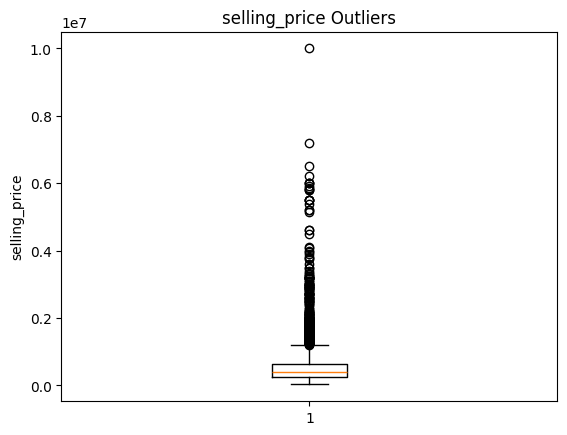

In [46]:
import matplotlib.pyplot as plt
plt.boxplot(car['selling_price'])
plt.title('selling_price Outliers')
plt.ylabel('selling_price')
plt.show()

In [47]:
x = car.drop(columns=['selling_price'])
y = car['selling_price']

In [48]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [49]:
x_train.shape

(5540, 12)

In [50]:
x_test.shape

(1386, 12)

In [51]:
x_train

,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,torque_value,brand
5586,2018,25000,Diesel,Individual,Manual,First Owner,23.00,1498.0,98.96,5.0,205.00,Ford
3468,2010,170000,Petrol,Individual,Manual,Second Owner,19.44,1248.0,81.83,5.0,NaN,Maruti
4935,2011,75500,Diesel,Individual,Manual,Second Owner,23.00,1396.0,90.00,5.0,22.40,Hyundai
2485,2009,138000,Diesel,Individual,Manual,Second Owner,19.30,1248.0,73.90,5.0,190.00,Maruti
4491,2003,200000,Diesel,Individual,Manual,Second Owner,13.10,1493.0,82.00,5.0,187.00,Hyundai
...,...,...,...,...,...,...,...,...,...,...,...,...
4286,2005,90000,Petrol,Individual,Manual,Second Owner,13.80,1299.0,70.00,5.0,10.70,Ford
5986,2009,71000,Petrol,Individual,Manual,First Owner,16.10,1197.0,85.00,5.0,113.00,Maruti
6021,2012,56246,Petrol,Dealer,Manual,First Owner,18.60,1197.0,85.80,5.0,114.00,Maruti
6268,2019,14548,Petrol,Dealer,Manual,First Owner,21.21,1197.0,81.80,5.0,113.00,Maruti


In [52]:
num_feature = [
    "year",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "torque_value",
    "seats"

]

cat_feature = [
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "brand"
]

In [53]:
from sklearn.pipeline import Pipeline

In [54]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [55]:
from sklearn.compose import ColumnTransformer

In [56]:
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

In [57]:
cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown= "ignore"))
])

In [58]:
preprocessor= ColumnTransformer([
    ("num", num_transformer, num_feature),
    ("col",cat_transformer, cat_feature)
])

In [59]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error,mean_squared_error

In [60]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators =300,
        random_state = 42,
        n_jobs = -1
    ))
])

In [61]:
model.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['year', 'km_driven',
                                                   'mileage', 'engine',
                                                   'max_power', 'torque_value',
                                                   'seats']),
                                                 ('col',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('one_hot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['fuel', 'seller_type',
                                                   'transmission', 'owner',
                                                   'brand'])])),
                ('model',
                 RandomForestRegressor(n_estimators=300, n_jobs=-1,
                                       random_state=42))])

In [62]:
y_pred = model.predict(x_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
print(f"R-squared: {r2}")
print(f"Mean Absolute Error: {mae}")
print(f"Mean Squared Error: {mse}")
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Root Mean Squared Error: {rmse}")

R-squared: 0.9285639944456818
Mean Absolute Error: 72102.12811301771
Mean Squared Error: 15667461035.374231
Root Mean Squared Error: 125169.72890988553


In [63]:
train_r2 = model.score(x_train, y_train)
test_r2 = model.score(x_test, y_test)

print("Train R2:", train_r2)
print("Test R2:", test_r2)

Train R2: 0.9861540370063053
Test R2: 0.9285639944456818


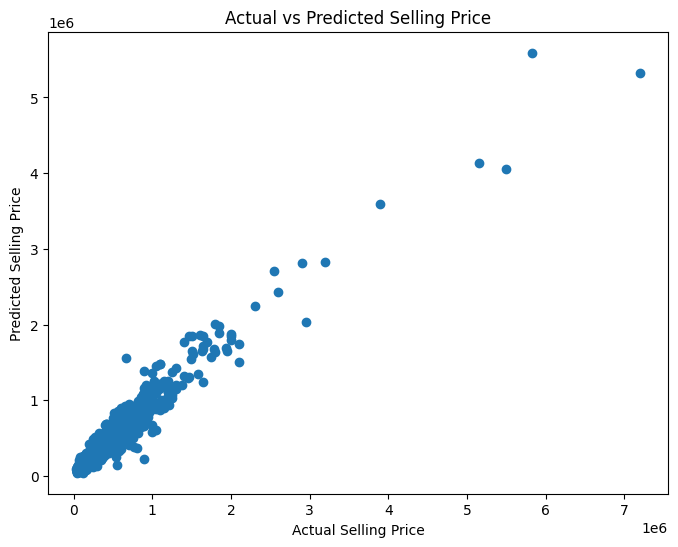

In [64]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Selling Price")
plt.show()

In [65]:
results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

print(results.head(10))

      Actual Price  Predicted Price
8077        550000     7.163600e+05
4094       1225000     1.040457e+06
6493        850000     8.545670e+05
4339         80000     1.673144e+05
2535        825000     7.231967e+05
7025        800000     9.476867e+05
3063        229999     3.041592e+05
1456         93150     2.338438e+05
7540        300000     2.397400e+05
3289        493000     5.247166e+05


In [66]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

results["Error"] = (
    results["Actual"] - results["Predicted"]
)

results["Absolute_Error"] = (
    results["Error"].abs()
)

print(
    results.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(10)
)

       Actual     Predicted         Error  Absolute_Error
2938  7200000  5.320960e+06  1.879040e+06    1.879040e+06
7930  5500000  4.053154e+06  1.446846e+06    1.446846e+06
132   5150000  4.132100e+06  1.017900e+06    1.017900e+06
1990  2950000  2.028728e+06  9.212723e+05    9.212723e+05
4592   667000  1.552650e+06 -8.856500e+05    8.856500e+05
6598   890000  2.211280e+05  6.688719e+05    6.688719e+05
4030  2100000  1.502267e+06  5.977333e+05    5.977333e+05
4391   900000  1.383083e+06 -4.830833e+05    4.830833e+05
2407  1050000  6.107889e+05  4.392111e+05    4.392111e+05
4650   800000  3.680966e+05  4.319034e+05    4.319034e+05


In [67]:
results["Price_Range"] = pd.cut(
    results["Actual"],
    bins=[0, 200000, 500000, 1000000, float("inf")],
    labels=[
        "Below 2 lakh",
        "2-5 lakh",
        "5-10 lakh",
        "Above 10 lakh"
    ]
)

print(
    results.groupby(
        "Price_Range",
        observed=True
    )["Absolute_Error"].mean()
)

Price_Range
Below 2 lakh      37552.205665
2-5 lakh          55095.244807
5-10 lakh         86670.133510
Above 10 lakh    238574.525799
Name: Absolute_Error, dtype: float64


In [70]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.7, 1.0]
}

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(x_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV MAE:", -search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters: {'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': None}
Best CV MAE: 79895.58786111284


In [72]:
best_model = search.best_estimator_

y_pred = best_model.predict(x_test)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    root_mean_squared_error
)

print("Test R2:", r2_score(y_test, y_pred))
print("Test MAE:", mean_absolute_error(y_test, y_pred))
print("Test RMSE:", root_mean_squared_error(y_test, y_pred))

Test R2: 0.9303258953932632
Test MAE: 70621.66426139265
Test RMSE: 123616.49587005426


In [73]:
print("Best CV MAE:", -search.best_score_)
print("Best parameters:", search.best_params_)

Best CV MAE: 79895.58786111284
Best parameters: {'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': None}


In [75]:
from sklearn.ensemble import ExtraTreesRegressor
extra_trees = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", ExtraTreesRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees.fit(x_train, y_train)

y_pred_extra = extra_trees.predict(x_test)

print("Extra Trees Regressor")
print("R2 Score:", r2_score(y_test, y_pred_extra))
print("MAE:", mean_absolute_error(y_test, y_pred_extra))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_extra)))

Extra Trees Regressor
R2 Score: 0.889705712051961
MAE: 77593.22851210518
RMSE: 155531.09911176548


In [77]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=2,
        loss="huber",
        random_state=42
    ))
])

gradient_boosting.fit(x_train, y_train)

y_pred_gb = gradient_boosting.predict(x_test)

print("Gradient Boosting Regressor")
print("R2 Score:", r2_score(y_test, y_pred_gb))
print("MAE:", mean_absolute_error(y_test, y_pred_gb))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_gb)))

Gradient Boosting Regressor
R2 Score: 0.9098507719600255
MAE: 77363.96274024149
RMSE: 140611.78988937326


In [78]:
results = {
    "Random Forest": [
        r2_score(y_test, y_pred),
        mean_absolute_error(y_test, y_pred),
        np.sqrt(mean_squared_error(y_test, y_pred))
    ],
    "Extra Trees": [
        r2_score(y_test, y_pred_extra),
        mean_absolute_error(y_test, y_pred_extra),
        np.sqrt(mean_squared_error(y_test, y_pred_extra))
    ],
    "Gradient Boosting": [
        r2_score(y_test, y_pred_gb),
        mean_absolute_error(y_test, y_pred_gb),
        np.sqrt(mean_squared_error(y_test, y_pred_gb))
    ]
}

comparison = pd.DataFrame(
    results,
    index=["R2 Score", "MAE", "RMSE"]
).T

print(comparison)

                   R2 Score           MAE           RMSE
Random Forest      0.930326  70621.664261  123616.495870
Extra Trees        0.889706  77593.228512  155531.099112
Gradient Boosting  0.909851  77363.962740  140611.789889


In [81]:
import joblib

final_model = search.best_estimator_

joblib.dump(final_model, "final_car_price_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [83]:
import joblib

final_model = joblib.load("final_car_price_model.pkl")

new_predictions = final_model.predict(x_test)

In [86]:


new_car = pd.DataFrame([{
    "year": 2018,
    "km_driven": 50000,
    "fuel": "Diesel",
    "seller_type": "Individual",
    "transmission": "Manual",
    "owner": "First Owner",
    "mileage": 20.5,
    "engine": 1248,
    "max_power": 74,
    "seats": 5,
    "brand": "Maruti",
    "torque_value": 1
}])

predicted_price = model.predict(new_car)

print("Predicted selling price:", round(predicted_price[0], 2))

Predicted selling price: 415080.81
